In [88]:
!rsync -avz root@103.82.192.49:~/top-k-husm-mg/benchmark/results/ ../results/vps

receiving incremental file list

sent 24 bytes  received 428 bytes  301.33 bytes/sec
total size is 7,204  speedup is 15.94


In [89]:
import importlib
import sys
from pathlib import Path

INPUT = "benchmark/results/vps/08_03/runs.csv"

HERE = Path.cwd()
if not (HERE / "utils").is_dir():
    for parent in (HERE, *HERE.parents):
        if (parent / "benchmark" / "visualize" / "utils").is_dir():
            HERE = parent / "benchmark" / "visualize"
            break
sys.path.insert(0, str(HERE))

import utils.report_plots as report_plots
import utils.report as report_mod
importlib.reload(report_plots)
importlib.reload(report_mod)
from utils.report import ReportViewer



In [90]:
# Toàn bộ phần đọc CSV / metric phái sinh / layout / export nằm trong class.
report = ReportViewer(INPUT)
# Tuỳ chọn, ví dụ: ReportViewer(INPUT, only_datasets=["dblp-multigraph"], max_cols=3, share_y="none")

print(report)
print("metrics:", ", ".join(report.metrics()))
display(report.coverage())


ReportViewer(datasets=1 ['bn-fly-drosophila'], rows=3, metrics=9, out_dir=/workspaces/top-k-husm-mg/benchmark/visualize/out/report)
metrics: time_s, mem_mb, mem_logger_mb, heap_mb, patterns, throughput, alloc_kb_per_pattern, cpu_wall_ratio, alloc_over_peak


,rows,mer,values,K,K values,bounds
dataset,,,,,,
bn-fly-drosophila,3,1,1,1,10,"CEU, EU, IVU"


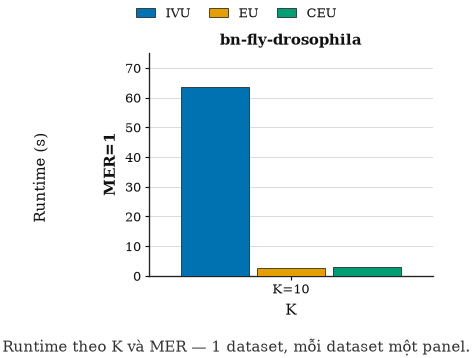

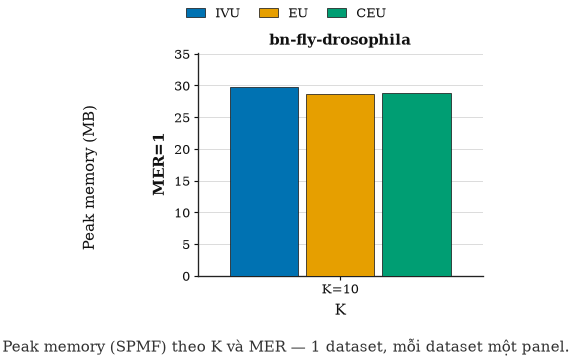

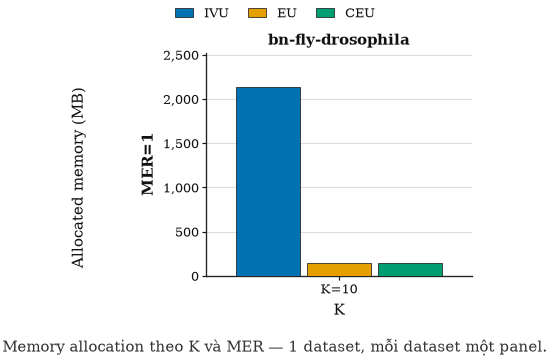

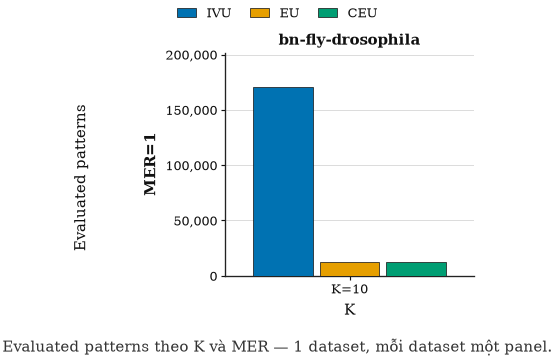

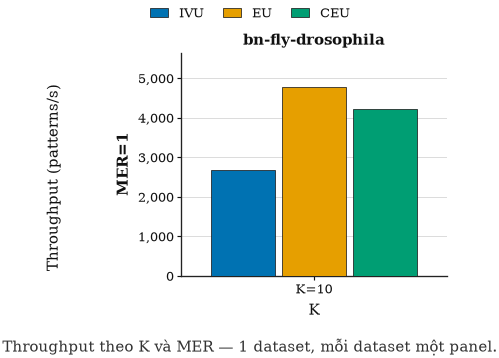

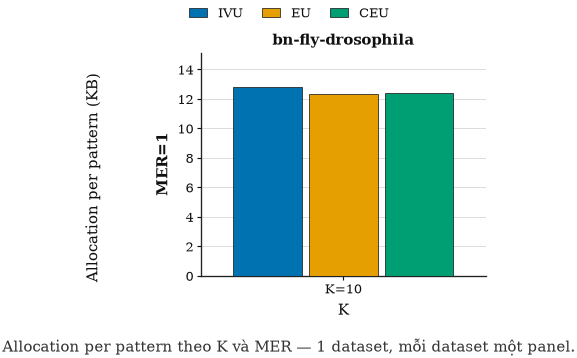

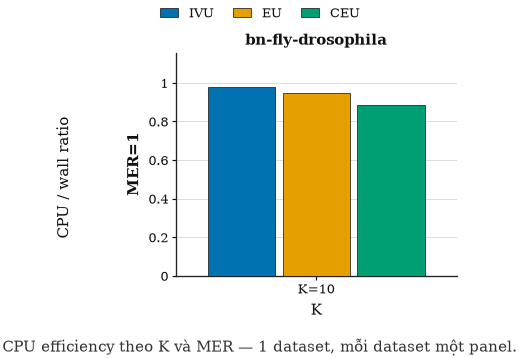

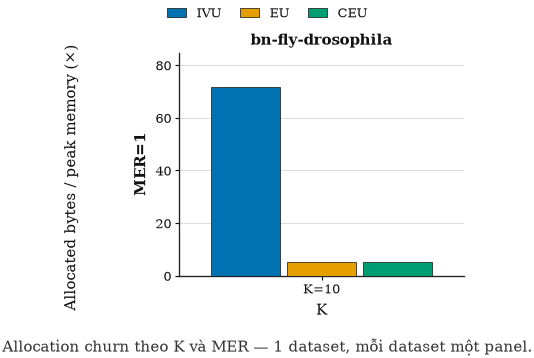

In [91]:
figs = report.plot_all()

# Muốn vẽ lẻ / tinh chỉnh thì gọi trực tiếp:
# report.plot("time_s")
# report.plot("mem_logger_mb", share_y="none", max_cols=2)
# report.plot_pooled("time_s")     # kiểu gộp mọi dataset (đối chiếu)


In [92]:
display(report.summary())
# report.save_summary()   # -> out/report/memory_summary.csv


peak_memory  peak_heap_mxbean  allocated  \
dataset           mer K  ieu_bound                                             
bn-fly-drosophila 1   10 CEU               28.8              28.6      147.4   
                         EU                28.6              28.3      146.4   
                         IVU               29.8              29.0     2134.9   

                                    alloc/peak_memory  
dataset           mer K  ieu_bound                     
bn-fly-drosophila 1   10 CEU                      5.1  
                         EU                       5.1  
                         IVU                     71.6